# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [9]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [10]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [11]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


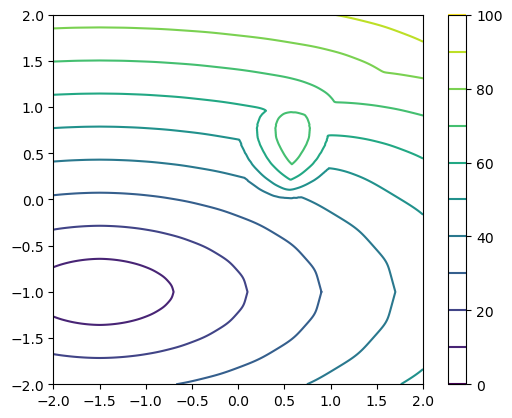

In [12]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [13]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


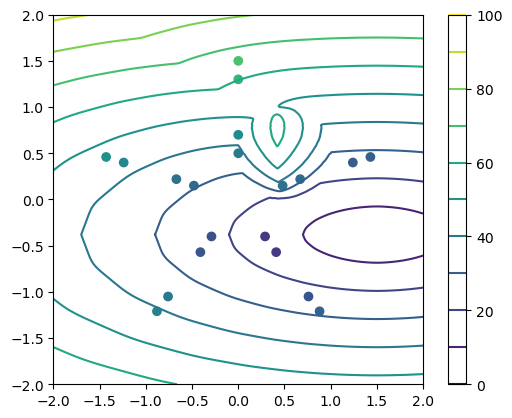

In [14]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [15]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

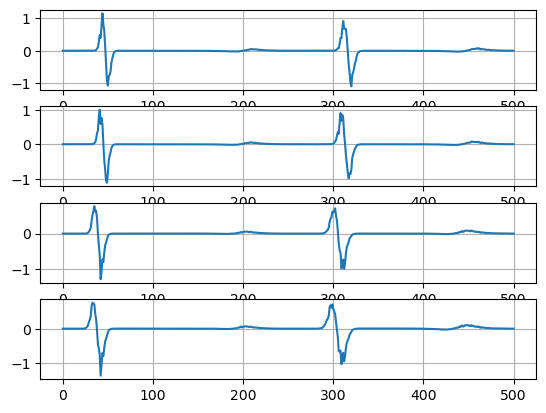

In [9]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [16]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy')
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [17]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
from tqdm import tqdm  # <-- IMPORTANTE: Aggiunto per la barra di progresso
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
X_mesh_vel, Y_mesh_vel = np.meshgrid(np.linspace(-2.0, 2.0, 201), np.linspace(-2.0, 2.0, 201))
X_mesh_100, Y_mesh_100 = np.meshgrid(np.linspace(-2.0, 2.0, 101), np.linspace(-2.0, 2.0, 101))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

# GRIGLIA 400X400
# meas_indices = []
# for j in range(5):
#     for i in range(4):
#         MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
#         i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
#         meas_indices.append((i_sel, j_sel))

# idx_400 = np.array(meas_indices)

# GRIGLIA 200X200
meas_indices_vel = []
for j in range(5):
    for i in range(4):
        MeasMat_vel = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_vel.argmin(), MeasMat_vel.shape)
        meas_indices_vel.append((i_sel, j_sel))

idx_vel = np.array(meas_indices_vel)

# GRIGLIA 100X100
# meas_indices_100 = []
# for j in range(5):
#     for i in range(4):
#         MeasMat_100 = (X_mesh_100 - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_100 - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
#         i_sel, j_sel = np.unravel_index(MeasMat_100.argmin(), MeasMat_100.shape)
#         meas_indices_100.append((i_sel, j_sel))

# idx_100 = np.array(meas_indices_100)

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = np.load('checkpoint2anisotropy.npy')

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] 

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (CORRETTA)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Se la correlazione era negativa, significa che i 4 sensori di ogni spline
    # nel dataset sono invertiti rispetto a Spline_spacing.
    
    t_beat1_ordered = []
    t_beat2_ordered = []
    
    for s in range(5): # Per ogni spline
        # Prendi i 4 tempi della spline s
        spline_times = raw_timings[s*4 : (s+1)*4]
        
        # PROVA A INVERTIRE QUI: 
        # Se il dataset è [Lontano -> Vicino], invertiamo per farlo diventare [Vicino -> Lontano]
        spline_times = spline_times[::-1] 
        
        for t in spline_times:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])
            
    measured_times_beat1.append(np.array(t_beat1_ordered, dtype=float))
    measured_times_beat2.append(np.array(t_beat2_ordered, dtype=float))


In [ ]:
import math
# ==========================================
# 4. FUNZIONE OBIETTIVO CON VELOCITÀ SFUMATA (TANH)
# ==========================================
def objective_velocities(velocities):
    v_base, v_slow = velocities
    total_mse = 0.0
    print(f"Testing velocities: v_base={v_base:.2f}, v_slow={v_slow:.2f}")
    
    # Parametro di ripidezza del bordo (k)
    # 50.0 rende il bordo netto ma matematicamente derivabile
    k = 50.0 
    
    for idx in range(5):
        xc, yc, r = reference_targets[idx]
        a_ratio = float(np.array(a_ratios_training[idx]**2).item())
        
        # # 1. Costruzione tensore di diffusione (Anisotropia)
        # theta0 = np.pi/2 # fiber_theta assumed 0
        # a = np.array([np.cos(theta0), np.sin(theta0)])
        # b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        # D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        # D_inv = np.linalg.inv(D)
        # sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        # La matrice D è sempre diagonale, si possono calcolare direttamente i sigma senza costruire D
        sigma_11 = 1.0
        sigma_12 = 0.0
        sigma_22 = a_ratio
        
        # 2. CREAZIONE CAMPO VELOCITÀ SFUMATO (Sostituisce il lambda)
        # Calcoliamo la distanza di ogni punto della mesh dal centro dell'ischemia
        # dist = np.sqrt((X_mesh_vel - xc)**2 + (Y_mesh_vel - yc)**2)
        
        # Funzione peso basata su tanh: 0 all'interno, 1 all'esterno
        # weight = 0.5 * (1 + np.tanh(k * (dist - r)))
        
        # Matrice delle velocità (vettorializzata, molto più veloce del lambda)
        # speed_grid = v_slow + weight * (v_base - v_slow)

        # speed_field = lambda x, y: v_slow + 0.5 * (1 + np.tanh(k * (np.hypot(x - xc, y - yc) - r))) * (v_base - v_slow)
        
        # costruiamo direttamente la matrice delle velocità senza passare da una funzione lambda, per efficienza
        dist = np.sqrt((X_mesh_vel - xc)**2 + (Y_mesh_vel - yc)**2)
        weight = 0.5 * (1 + np.tanh(k * (dist - r)))
        speed_grid = v_slow + weight * (v_base - v_slow)
        
        # NOTA: anisotropic_FMM_GPT deve ora accettare 'speed_grid' (matrice) 
        # invece di 'speed_field' (funzione). 
        # Se la tua FMM accetta solo funzioni, passagli: lambda x, y: speed_grid
        
        # --- SIMULAZIONE BATTITO 1 ---
        x0, y0 = impulse_sites[idx][0]
        t0 = starting_times[idx][0]/1000.0
        
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh_vel, Y_mesh_vel, speed_grid, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times1 = sim_beat1[idx_vel[:, 0], idx_vel[:, 1]]
        sim_times1 = sim_times1 - np.nanmin(sim_times1)
        meas_times1 = measured_times_beat1[idx]
        meas_times1 = meas_times1 - np.nanmin(meas_times1)
        
        mask1 = ~np.isnan(meas_times1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_times1[mask1])**2)
            
        # --- SIMULAZIONE BATTITO 2 ---
        x1, y1 = impulse_sites[idx][1]
        t1 = starting_times[idx][1]/1000.0
        
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh_vel, Y_mesh_vel, speed_grid, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times2 = sim_beat2[idx_vel[:, 0], idx_vel[:, 1]]
        sim_times2 = sim_times2 - np.nanmin(sim_times2)
        meas_times2 = measured_times_beat2[idx]
        meas_times2 = meas_times2 - np.nanmin(meas_times2)
        
        mask2 = ~np.isnan(meas_times2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_times2[mask2])**2)
        
    return total_mse

In [102]:
# ==========================================
# 5. AVVIO OTTIMIZZAZIONE
# ==========================================
initial_guess = [80.0, 20.0] 
bounds = [(40.0, 150.0), (5.0, 40.0)] 

print("Inizio calibrazione delle velocità (su 2 battiti per paziente)...")
pbar = tqdm(desc="Valutazioni Funzione Obiettivo", unit="eval")
# Funzione wrapper per aggiornare la barra ad ogni chiamata
def objective_with_pbar(velocities):
    pbar.update(1)
    # Mostra i valori correnti in tempo reale nella barra
    pbar.set_postfix({"v_base": f"{velocities[0]:.3f}", "v_slow": f"{velocities[1]:.3f}"})
    return objective_velocities(velocities)

result = minimize(objective_with_pbar, initial_guess, method='Nelder-Mead', bounds=bounds, options={'xatol': 1.0, 'fatol': 0.1})
pbar.close()

if result.success:
    print(f"\n✅ Ottimizzazione convergente!")
    print(f"Velocità tessuto sano (v_base): {result.x[0]:.2f}")
    print(f"Velocità tessuto lento (v_slow): {result.x[1]:.2f}")
else:
    print("\n❌ L'ottimizzatore non ha trovato un minimo:", result.message)

Inizio calibrazione delle velocità (su 2 battiti per paziente)...


Testing velocities: v_base=80.00, v_slow=20.00


Testing velocities: v_base=84.00, v_slow=20.00


Testing velocities: v_base=80.00, v_slow=21.00


Testing velocities: v_base=76.00, v_slow=21.00


Testing velocities: v_base=72.00, v_slow=21.50


... (7 outputs left out)

Testing velocities: v_base=68.00, v_slow=21.00


Testing velocities: v_base=71.00, v_slow=20.62


Valutazioni Funzione Obiettivo: 14eval [04:55, 21.13s/eval, v_base=71.000, v_slow=20.625]


✅ Ottimizzazione convergente!
Velocità tessuto sano (v_base): 70.00
Velocità tessuto lento (v_slow): 21.25


In [103]:
# ==========================================
# 6. SALVATAGGIO DELLE VELOCITÀ STIMATE
# ==========================================
if result.success:
    EST_V_BASE = result.x[0]
    EST_V_SLOW = result.x[1]

--- SCENARIO 1 BATTITO 1 ---
Huber Loss: 2.7950 | Corr: 0.9849 | Costo Tot: 3.2484
--- SCENARIO 1 BATTITO 2 ---
Huber Loss: 20.0798 | Corr: 0.9644 | Costo Tot: 21.1483
--- VERIFICA SPAZIALE SCENARIO 1 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            38.00 |                    1.2341
      1 |            39.00 |                    1.4127
      2 |            45.00 |                    1.9953
      3 |            48.00 |                    2.1809
      4 |            57.00 |                    1.2211
      5 |            61.00 |                    1.4077
      6 |            70.00 |                    1.9833
      7 |            74.00 |                    2.1781
      8 |            51.00 |                    0.7866
      9 |            54.00 |                    0.8674
     10 |            49.00 |                    1.2827
     11 |            49.00 |                    1.4427
     12 |            23.0

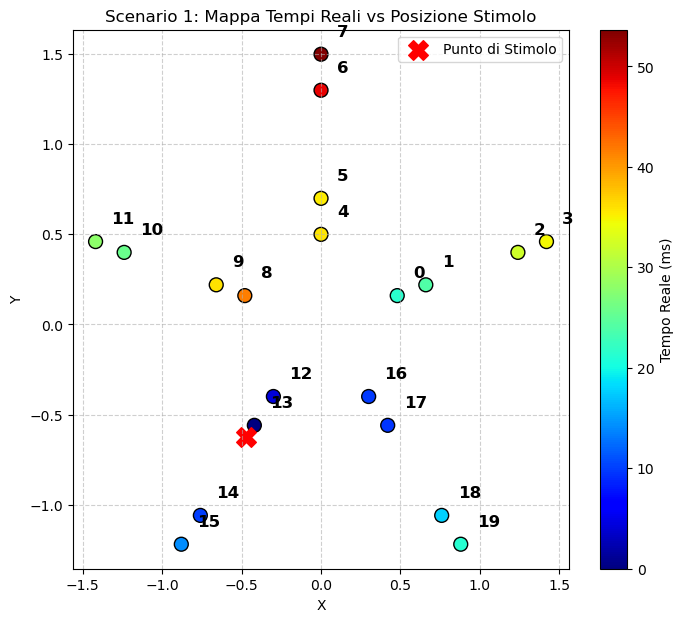

--- SCENARIO 2 BATTITO 1 ---
Huber Loss: 2.1301 | Corr: 0.9672 | Costo Tot: 3.1154
--- SCENARIO 2 BATTITO 2 ---
Huber Loss: 12.6095 | Corr: 0.9905 | Costo Tot: 12.8932
--- VERIFICA SPAZIALE SCENARIO 2 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            17.00 |                    2.0270
      1 |            23.00 |                    2.1899
      2 |            44.00 |                    2.7296
      3 |            48.00 |                    2.9052
      4 |            22.00 |                    2.0702
      5 |            29.00 |                    2.2557
      6 |            51.00 |                    2.8243
      7 |            58.00 |                    3.0165
      8 |             9.00 |                    1.6004
      9 |            13.00 |                    1.6333
     10 |            23.00 |                    1.8582
     11 |            26.00 |                    1.9652
     12 |            13.0

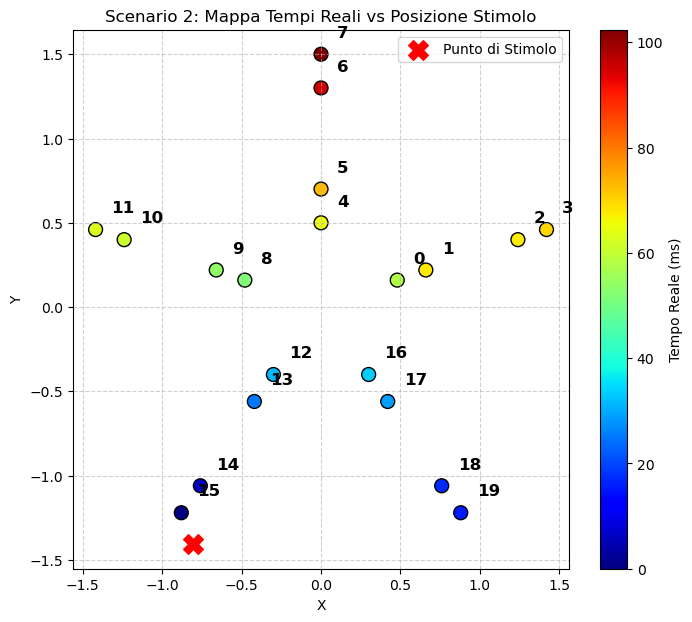

--- SCENARIO 3 BATTITO 1 ---
Huber Loss: 1.3763 | Corr: 0.9806 | Costo Tot: 1.9595
--- SCENARIO 3 BATTITO 2 ---
Huber Loss: 8.9874 | Corr: 0.9742 | Costo Tot: 9.7623
--- VERIFICA SPAZIALE SCENARIO 3 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            20.00 |                    0.3864
      1 |            22.00 |                    0.5073
      2 |            28.00 |                    1.0385
      3 |            30.00 |                    1.2202
      4 |            24.00 |                    0.8263
      5 |            27.00 |                    1.0052
      6 |            34.00 |                    1.5728
      7 |            36.00 |                    1.7668
      8 |            22.00 |                    0.9642
      9 |            25.00 |                    1.1534
     10 |            32.00 |                    1.7591
     11 |            35.00 |                    1.9487
     12 |            15.00 

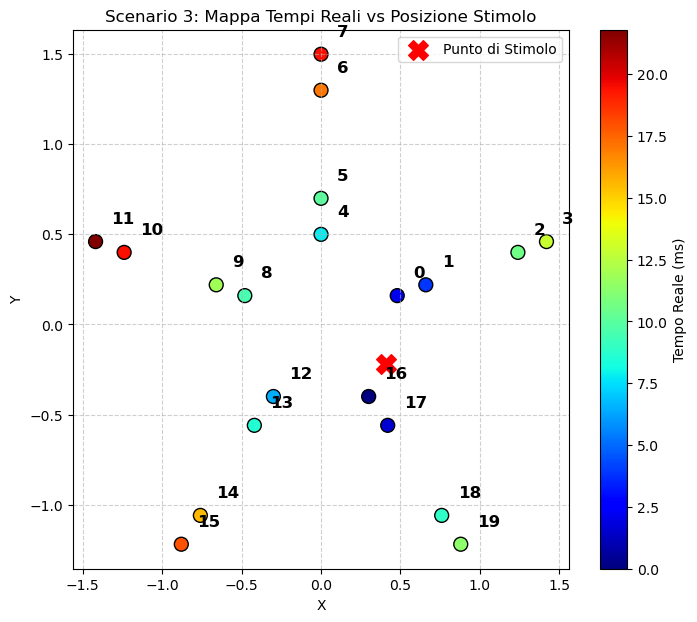

--- SCENARIO 4 BATTITO 1 ---
Huber Loss: 0.8495 | Corr: 0.9959 | Costo Tot: 0.9723


--- SCENARIO 4 BATTITO 2 ---
Huber Loss: 7.8473 | Corr: 0.9969 | Costo Tot: 7.9415
--- VERIFICA SPAZIALE SCENARIO 4 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            33.00 |                    1.7410
      1 |            33.00 |                    1.7189
      2 |            38.00 |                    1.7751
      3 |            40.00 |                    1.8377
      4 |            34.00 |                    2.2827
      5 |            36.00 |                    2.4495
      6 |            43.00 |                    2.9747
      7 |            46.00 |                    3.1557
      8 |            29.00 |                    2.3523
      9 |            30.00 |                    2.5289
     10 |            35.00 |                    3.1009
     11 |            36.00 |                    3.2833
     12 |            21.00 |                    1.8760
     13 |            20.00 |                    1.9059


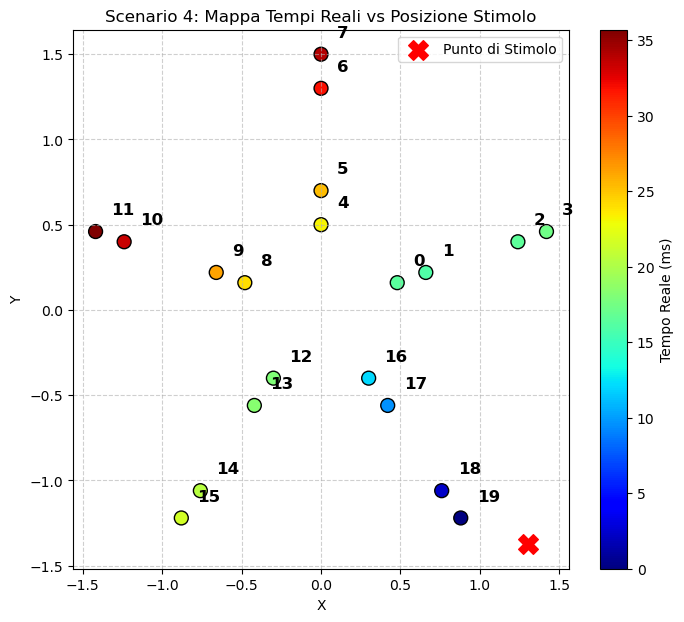

--- SCENARIO 5 BATTITO 1 ---
Huber Loss: 1.7091 | Corr: 0.9897 | Costo Tot: 2.0168
--- SCENARIO 5 BATTITO 2 ---
Huber Loss: 5.0765 | Corr: 0.9758 | Costo Tot: 5.8027
--- VERIFICA SPAZIALE SCENARIO 5 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            32.00 |                    2.0164
      1 |            30.00 |                    2.2002
      2 |            24.00 |                    2.7915
      3 |            22.00 |                    2.9783
      4 |            29.00 |                    1.8843
      5 |            26.00 |                    2.0422
      6 |            20.00 |                    2.5516
      7 |            20.00 |                    2.7296
      8 |            39.00 |                    1.3249
      9 |            39.00 |                    1.2900
     10 |            42.00 |                    1.3505
     11 |            43.00 |                    1.4266
     12 |            49.00 

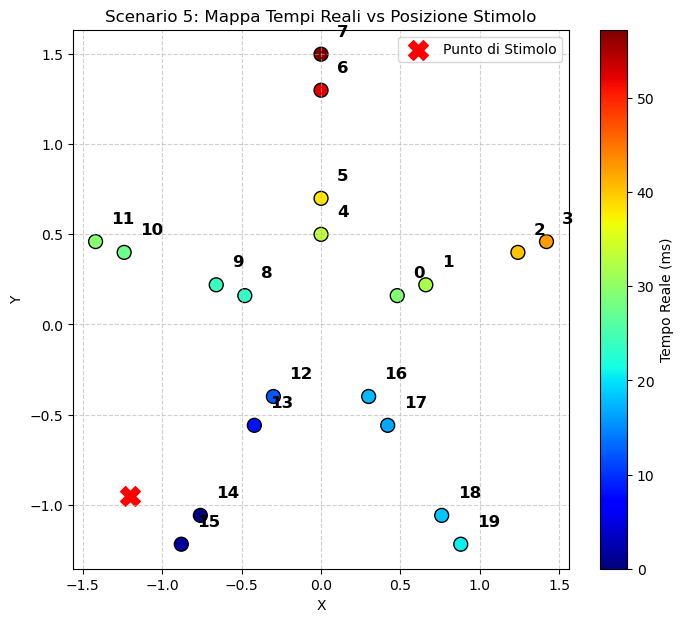

In [ ]:
from scipy.stats import pearsonr
import numpy as np
a_ratios_training = np.load('checkpoint2anisotropy.npy')
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy')
starting_times = np.load('checkpoint2starting.npy') 
reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]]

# Parametri per la nuova metrica
lam_corr = 150.0  # Peso della correlazione
delta_huber = 1.5 # Soglia in ms per la Huber Loss

for idx in range(5):
    a_ratio = np.array(a_ratios_training[idx]**2).item()
    xc, yc, r = reference_targets[idx]

    sigma_11 = 1.0
    sigma_12 = 0.0
    sigma_22 = a_ratio

    # Assicurati che speed_field sia definito prima o usa la speed_grid/matrix 
    # come abbiamo discusso per efficienza (qui mantengo il tuo riferimento)
    x_0, y_0 = impulse_sites[idx][0]
    x_1, y_1 = impulse_sites[idx][1]
    t_0 = starting_times[idx][0]/1000
    t_1 = starting_times[idx][1]/1000

    # --- SIMULAZIONE E CALCOLO ERRORE BATTITO 1 ---
    sim_beat1 = anisotropic_FMM_GPT(
        x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )
    sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
    sim_times1 = (sim_times1 - np.nanmin(sim_times1)) * 1e3 # Conversione in ms
    
    meas_rel1 = measured_times_beat1[idx]
    meas_rel1 = meas_rel1 - np.nanmin(meas_rel1)
    
    mask1 = ~np.isnan(meas_rel1)
    if np.any(mask1):
        s1 = sim_times1[mask1]
        m1 = meas_rel1[mask1]
        
        # 1. Huber Loss Battito 1
        diff1 = np.abs(s1 - m1)
        huber1 = np.where(diff1 <= delta_huber, 0.5 * diff1**2, delta_huber * (diff1 - 0.5 * delta_huber))
        val_huber1 = np.mean(huber1)
        
        # 2. Correlazione Battito 1
        corr1, _ = pearsonr(s1, m1)
        cost1 = val_huber1 + lam_corr * (1.0 - corr1)
        
        print(f"--- SCENARIO {idx+1} BATTITO 1 ---")
        print(f"Huber Loss: {val_huber1:.4f} | Corr: {corr1:.4f} | Costo Tot: {cost1:.4f}")

    # --- SIMULAZIONE E CALCOLO ERRORE BATTITO 2 ---
    sim_beat2 = anisotropic_FMM_GPT(
        x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )
    sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
    sim_times2 = (sim_times2 - np.nanmin(sim_times2)) * 1e3 # Conversione in ms

    meas_rel2 = measured_times_beat2[idx]
    meas_rel2 = meas_rel2 - np.nanmin(meas_rel2)

    mask2 = ~np.isnan(meas_rel2)
    if np.any(mask2):
        s2 = sim_times2[mask2]
        m2 = meas_rel2[mask2]
        
        # 1. Huber Loss Battito 2
        diff2 = np.abs(s2 - m2)
        huber2 = np.where(diff2 <= delta_huber, 0.5 * diff2**2, delta_huber * (diff2 - 0.5 * delta_huber))
        val_huber2 = np.mean(huber2)
        
        # 2. Correlazione Battito 2
        corr2, _ = pearsonr(s2, m2)
        cost2 = val_huber2 + lam_corr * (1.0 - corr2)
        
        print(f"--- SCENARIO {idx+1} BATTITO 2 ---")
        print(f"Huber Loss: {val_huber2:.4f} | Corr: {corr2:.4f} | Costo Tot: {cost2:.4f}")

    # --- RESTO DEL TUO CODICE DI VISUALIZZAZIONE ---
    x_stim, y_stim = impulse_sites[idx][1]
    # ... (Il resto del codice per scatter plot e verifica distanze rimane uguale)

    x_stim, y_stim = impulse_sites[idx][1]

    # 2. Tempi reali (normalizzati)
    meas_rel = measured_times_beat1[idx] 

    # 3. Calcoliamo la distanza EUCLIDEA pura tra stimolo e sensori sulla tua mesh
    # Usiamo le coordinate estratte tramite i tuoi meas_indices_vel
    distanze_mesh = []
    for i, j in meas_indices_vel:
        d = np.sqrt((X_mesh_vel[i, j] - x_stim)**2 + (Y_mesh_vel[i, j] - y_stim)**2)
        distanze_mesh.append(d)

    distanze_mesh = np.array(distanze_mesh)

    # 4. Confronto
    print(f"--- VERIFICA SPAZIALE SCENARIO {idx+1} ---")
    print("Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)")
    print("-" * 50)
    for s in range(20):
        print(f"{s:7d} | {meas_rel[s]:16.2f} | {distanze_mesh[s]:25.4f}")

    # 5. Correlazione
    correlation = np.corrcoef(meas_rel2, distanze_mesh)[0, 1]
    print("-" * 50)
    print(f"Correlazione Tempo/Distanza: {correlation:.4f}")

    # Estraiamo gli indici i e j dalla tua lista di tuple
    meas_indices_vel_i = [idx[0] for idx in meas_indices_vel]
    meas_indices_vel_j = [idx[1] for idx in meas_indices_vel]

    plt.figure(figsize=(8,7))

    # Disegniamo i sensori colorandoli in base al tempo reale di attivazione
    sc = plt.scatter(X_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    Y_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    c=sim_times2, cmap='jet', s=100, edgecolors='k')
    # Disegniamo il punto di stimolo (focal point)
    plt.scatter(x_stim, y_stim, color='red', marker='X', s=200, label='Punto di Stimolo')

    # Aggiungiamo i numeri dei sensori per capire se l'ordine è quello che pensiamo
    for s in range(20):
        plt.text(X_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                Y_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                str(s), fontsize=12, fontweight='bold')

    plt.colorbar(sc, label='Tempo Reale (ms)')
    plt.title(f"Scenario {idx+1}: Mappa Tempi Reali vs Posizione Stimolo")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

### signature of the function ###

In [ ]:
from scipy.stats import qmc
import numpy as np
from tqdm import tqdm
from scipy.optimize import minimize
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args

EST_V_BASE = 67.96
EST_V_SLOW = 19.80
def find_best_start_bayesian(patient_cost_func):
    f = patient_cost_func([-0.407, 0.299, 0.578, 2.0]) # MSE di riferimento (target)
    print(f"Reference target MSE: {f:.4f}")
    print("🚀 Ricerca Globale Bayesiana (Mappatura Probabilistica)...")
    
    # Definiamo lo spazio di ricerca STATISTICAMENTE SIGNIFICATIVO
    # Non ci limitiamo al dataset, ma alla fisica del problema
    search_space = [
        Real(-1.5, 1.5, name='xc'),           # Posizione X 
        Real(-1.5, 1.5, name='yc'),           # Posizione Y
        Real(0.02, 1.2, name='r'),            # Raggio (da quasi zero a molto grande)
        Real(1.0, 5.0, name='a_ratio_sqrt')   # Anisotropia (copre fino a 25.0 fisico)
    ]

    # gp_minimize costruisce un "Surrogate Model" della tua FMM
    res = gp_minimize(
        patient_cost_func, 
        search_space, 
        n_calls=100,               # Numero totale di simulazioni (bilanciato)
        n_initial_points=40,      # Punti iniziali per "capire" il terreno
        acq_func='EI',            # Expected Improvement: cerca dove l'errore cala davvero
        random_state=42
    )

    print(f"📍 Optimum Globale stimato: Pos=[{res.x[0]:.2f}, {res.x[1]:.2f}], R={res.x[2]:.2f}, Aniso={res.x[3]:.2f}")
    print(f"📉 MSE minimo trovato in fase globale: {res.fun:.4f}")
    
    return res.x

# def find_best_start(patient_cost_func):
#     print("🚀 Scanning globale dello spazio (Pos, R, Aniso)...")
#     best_mse = float('inf')
#     best_params = [0, 0, 0.5, 5.0]
#     mse_l = patient_cost_func([-0.407, 0.299, 0.578, 2.0])

#     # Generiamo 100 combinazioni casuali entro i bounds ORIGINALI (Tutto continuo)
#     # x, y in [-1.5, 1.5], r in [0.2, 0.8], aniso in [2.0, 5.0]
#     np.random.seed(42) # Per ripetibilità
#     random_starts = np.random.uniform(
#         low=[-1.5, -1.5, 0.2, 2.0], 
#         high=[1.5, 1.5, 0.8, 5.0], 
#         size=(100, 4)
#     )

#     mse_l = patient_cost_func([-0.407, 0.299, 0.578, 2.0])
#     print(f"Reference target MSE: {mse_l:.4f}")

#     for p in random_starts:
#         mse = patient_cost_func(p)
#         print(f"Tested start: Pos=({p[0]:.2f}, {p[1]:.2f}), R={p[2]:.2f}, Aniso={p[3]:.1f} -> MSE={mse:.4f}")
#         if mse < best_mse:
#             best_mse = mse
#             best_params = p
            
#     print(f"📍 Punto di partenza ottimale trovato: Pos={best_params[:2]}, R={best_params[2]:.2f}, Aniso={best_params[3]:.1f}")
#     return best_params

# ==========================================
# 7. FUNZIONE FINALE (FASE 2) - VERSIONE CON SOLO REGOLARIZZAZIONI
# ==========================================
def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    global EST_V_BASE, EST_V_SLOW

    # --- 1. ESTRAZIONE TEMPI (CORRETTA) ---
    raw_timings = GroupSolutionCP1(signals_event)

    # Creiamo liste temporanee per riordinare i dati
    t_beat1_ordered = []
    t_beat2_ordered = []

    # Iteriamo su ogni spline (5 spline in totale)
    for s in range(5):
        # Estraiamo i 4 sensori della spline corrente (es. sensori 0,1,2,3)
        spline_chunk = raw_timings[s*4 : (s+1)*4]
        
        # INVERTIAMO l'ordine radiale del blocco
        spline_chunk_reversed = spline_chunk[::-1]
        
        for t in spline_chunk_reversed:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])

    meas_beat1 = np.array(t_beat1_ordered, dtype=float)
    meas_beat2 = np.array(t_beat2_ordered, dtype=float)
    meas_beat1 = meas_beat1 - np.nanmin(meas_beat1)
    meas_beat2 = meas_beat2 - np.nanmin(meas_beat2)
        
    # --- 2. ALLINEAMENTO TEMPI (in secondi) ---
    t_0 = t_0 / 1000.0
    t_1 = t_1 / 1000.0 

    pbar_p = tqdm(desc="🔍 Ricerca Ischemia", unit="eval", leave=False)

    def patient_cost_with_pbar(params):
        pbar_p.update(1)
        res_cost = patient_cost(params)
        pbar_p.set_postfix({"MSE": f"{res_cost:.2f}", "R": f"{params[2]:.2f}"})
        return res_cost   

# --- 3. FUNZIONE DI OTTIMIZZAZIONE AGGIORNATA ---
    def patient_cost(params):
        from scipy.stats import pearsonr
        
        xc, yc, r, a_ratio_sqrt = params
        a_ratio = float(np.array(a_ratio_sqrt**2).item())
        
        total_error = 0.0
        # Peso della correlazione: quanto conta la "forma" rispetto ai ms?
        lam_corr = 150.0 
        
        # --- CALCOLO PENALITÀ (Invariato come richiesto) ---
        penalty = 0.0
        weight_penalty = 1000.0
        if r > 1.0:
            penalty += weight_penalty * abs(r - 1.0)
        dist_center = np.hypot(xc, yc)
        if dist_center > 1.5:
            penalty += weight_penalty * abs(dist_center - 1.5)
        if a_ratio_sqrt > 4.0:
            penalty += 100.0 * abs(a_ratio_sqrt - 4.0)

        k = 50.0 # Transizione fisica
        sigma_11, sigma_12, sigma_22 = 1.0, 0.0, a_ratio
        
        dist = np.hypot(X_mesh_vel - xc, Y_mesh_vel - yc)
        speed_matrix = EST_V_SLOW + 0.5 * (1 + np.tanh(k * (dist - r))) * (EST_V_BASE - EST_V_SLOW)

        # Iteriamo sui due battiti per pulire il codice
        sim_configs = [(x_0, y_0, t_0, meas_beat1), (x_1, y_1, t_1, meas_beat2)]
        
        for x_imp, y_imp, t_imp, meas_actual in sim_configs:
            # Simulazione
            sim_raw = anisotropic_FMM_GPT(
                x_imp, y_imp, t_imp, X_mesh_vel, Y_mesh_vel, speed_matrix, 
                sigma_11, sigma_12, sigma_22
            ) * 1000.0 
            
            sim_punti = sim_raw[idx_vel[:, 0], idx_vel[:, 1]]
            sim_norm = sim_punti - np.nanmin(sim_punti)
            mask = ~np.isnan(meas_actual)
            
            if np.any(mask):
                s = sim_norm[mask]
                m = meas_actual[mask]
                
                # 1. HUBER LOSS (Invece del semplice MSE)
                # Più robusta agli outlier, rende la funzione più liscia
                diff = np.abs(s - m)
                delta = 1.5 # Soglia ms
                huber = np.where(diff <= delta, 0.5 * diff**2, delta * (diff - 0.5 * delta))
                mse_part = np.mean(huber)
                
                # 2. CORRELAZIONE DI PEARSON
                # pearsonr restituisce (coefficiente, p-value). Prendiamo il coeff [0]
                # Se i dati sono costanti o piatti, la corr è indefinita (usiamo 0)
                if np.std(s) > 1e-6 and np.std(m) > 1e-6:
                    corr_coeff, _ = pearsonr(s, m)
                else:
                    corr_coeff = 0.0
                
                # Vogliamo minimizzare (1 - corr), quindi 0 se identici, 2 se opposti
                corr_term = lam_corr * (1.0 - corr_coeff)
                
                total_error += (mse_part + corr_term)

        final_cost = total_error + penalty
        
        # Debugging per vedere quale termine domina
        print(f"Test: ({xc:.2f}, {yc:.2f}), R={r:.2f}, Aniso={a_ratio_sqrt:.2f} -> MSE_Huber: {total_error-corr_term:.2f}, Corr_Term: {corr_term:.2f}, Penalty: {penalty:.2f}, Total Cost: {final_cost:.2f}")

        return final_cost

    # --- 4. ESECUZIONE ---
    initial_guess = find_best_start_bayesian(patient_cost)
    
    # Manteniamo confini ragionevoli (il cuore virtuale è in [-2, 2])
    bounds = [(-2.0, 2.0), (-2.0, 2.0), (0.01, 1.5), (1.0, 5.0)]
    
    # Ottimizzazione locale a partire dal seed migliore
    res_patient = minimize(patient_cost_with_pbar, initial_guess, method='Nelder-Mead', bounds=bounds, options={
        'xatol': 0.02,
        'fatol': 0.1,
        'maxiter': 300,  # Aumentato per permettere la convergenza sul gradiente liscio
        'adaptive': True
    })
    
    pbar_p.close() # Chiudiamo la barra del paziente
    return [res_patient.x[0], res_patient.x[1], res_patient.x[2]]

In [113]:
# ==========================================
# TEST RAPIDO SUL PRIMO PAZIENTE (SCENARIO 1)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 1) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 0

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 1) ===

Avvio simulazione. Elaborazione in corso...



🔍 Ricerca Ischemia: 0eval [00:00, ?eval/s]

Test: (-0.41, 0.30), R=0.58, Aniso=2.00 -> MSE_Huber: 19.49, Corr_Term: 3.97, Penalty: 0.00, Total Cost: 23.47
Reference target MSE: 23.4669
🚀 Ricerca Globale Bayesiana (Mappatura Probabilistica)...


KeyboardInterrupt: 

In [121]:
# =============================================
# TEST RAPIDO SUL SECONDO PAZIENTE (SCENARIO 4)
# =============================================

print("=== AVVIO TEST SINGOLO (Scenario 4) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 3

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 4) ===

Avvio simulazione. Elaborazione in corso...



Test: (-0.41, 0.30), R=0.58, Aniso=2.00 -> MSE_Huber: 61.34, Corr_Term: 13.81, Penalty: 0.00, Total Cost: 75.16
Reference target MSE: 75.1552
🚀 Ricerca Globale Bayesiana (Mappatura Probabilistica)...
Test: (0.89, -0.95), R=0.94, Aniso=3.39 -> MSE_Huber: 145.03, Corr_Term: 24.36, Penalty: 0.00, Total Cost: 169.39
Test: (-0.16, -1.20), R=0.56, Aniso=2.33 -> MSE_Huber: 76.14, Corr_Term: 11.12, Penalty: 0.00, Total Cost: 87.27
Test: (-1.07, 0.45), R=0.09, Aniso=3.89 -> MSE_Huber: 148.74, Corr_Term: 27.71, Penalty: 0.00, Total Cost: 176.45
Test: (1.32, -1.50), R=1.19, Aniso=3.47 -> MSE_Huber: 159.19, Corr_Term: 29.56, Penalty: 684.29, Total Cost: 873.04
Test: (0.33, -1.48), R=0.05, Aniso=3.10 -> MSE_Huber: 106.89, Corr_Term: 23.81, Penalty: 16.26, Total Cost: 146.97
Test: (-0.30, -1.36), R=1.17, Aniso=1.93 -> MSE_Huber: 97.47, Corr_Term: 27.73, Penalty: 169.03, Total Cost: 294.24
Test: (-1.23, 0.36), R=0.47, Aniso=4.93 -> MSE_Huber: 208.93, Corr_Term: 26.89, Penalty: 93.29, Total Cost: 329.

📍 Optimum Globale stimato: Pos=[0.64, -0.73], R=0.25, Aniso=1.00
📉 MSE minimo trovato in fase globale: 5.1303


Test: (0.64, -0.73), R=0.25, Aniso=1.00 -> MSE_Huber: 4.61, Corr_Term: 0.52, Penalty: 0.00, Total Cost: 5.13


Test: (0.68, -0.73), R=0.25, Aniso=1.00 -> MSE_Huber: 4.59, Corr_Term: 0.40, Penalty: 0.00, Total Cost: 5.00


Test: (0.64, -0.77), R=0.25, Aniso=1.00 -> MSE_Huber: 4.58, Corr_Term: 0.59, Penalty: 0.00, Total Cost: 5.16


... (96 outputs left out)

Test: (1.01, -0.89), R=0.30, Aniso=1.04 -> MSE_Huber: 3.66, Corr_Term: 0.31, Penalty: 0.00, Total Cost: 3.98


Test: (1.03, -0.92), R=0.30, Aniso=1.04 -> MSE_Huber: 3.61, Corr_Term: 0.36, Penalty: 0.00, Total Cost: 3.97


Test: (1.04, -0.94), R=0.30, Aniso=1.04 -> MSE_Huber: 3.66, Corr_Term: 0.35, Penalty: 0.00, Total Cost: 4.01


Test: (1.02, -0.90), R=0.30, Aniso=1.04 -> MSE_Huber: 3.64, Corr_Term: 0.32, Penalty: 0.00, Total Cost: 3.96

✅ Test Completato!
Target Reale  : Centro [ 0.197, -0.242], Raggio: 0.042
Target Stimato: Centro [ 1.023, -0.913], Raggio: 0.299
Errore Centro : 1.0643 cm
Errore Raggio : 0.2568 cm


In [122]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# GRAFICO 1: VISUALIZZAZIONE GEOMETRICA
# ==========================================
def plot_geometric_solution(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh):
    """
    Sovrappone le circonferenze geometriche della lesione reale e di quella stimata,
    mostrando la dislocazione spaziale dei sensori e dei punti di stimolo.
    """
    true_x, true_y, true_r = true_target
    pred_x, pred_y, pred_r = pred_target
    x0, y0, x1, y1 = impulses

    fig, ax = plt.subplots(figsize=(8, 8))

    # Disegna la lesione reale
    circle_true = plt.Circle((true_x, true_y), true_r, color='green', fill=False, linewidth=2.5, linestyle='--', label='Lesione Reale (Ground Truth)')
    ax.add_patch(circle_true)

    # Disegna la lesione stimata
    circle_pred = plt.Circle((pred_x, pred_y), pred_r, color='red', fill=False, linewidth=2.5, label='Lesione Stimata (Ottimizzatore)')
    ax.add_patch(circle_pred)

    # Estrae le coordinate spaziali dei sensori dalla mesh
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori di misurazione')

    # Posiziona i due punti di stimolo (impulsi)
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, label='Punti di stimolo (t0, t1)')

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Confronto Geometrico: Lesione Reale vs Stimata")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.grid(True, linestyle=':', alpha=0.7)
    
    # Posiziona la legenda fuori dal grafico per non coprire i dati
    ax.legend(loc='upper right', bbox_to_anchor=(1.5, 1))
    plt.show()

# ==========================================
# GRAFICO 2: MAPPA DI CALORE (CAMPO DI VELOCITÀ)
# ==========================================
def plot_velocity_heatmap(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh, v_base, v_slow):
    """
    Ricostruisce la matrice delle velocità (con transizione tanh) generata dall'ottimizzatore
    e la mappa come contour plot per visualizzare fisicamente l'ostacolo affrontato dall'onda.
    """
    pred_x, pred_y, pred_r = pred_target
    true_x, true_y, true_r = true_target
    x0, y0, x1, y1 = impulses

    # Ricrea il campo vettoriale continuo esattamente come fatto nel "patient_cost"
    k = 25.0
    dist = np.hypot(X_mesh - pred_x, Y_mesh - pred_y)
    speed_grid = v_slow + 0.5 * (1 + np.tanh(k * (dist - pred_r))) * (v_base - v_slow)

    fig, ax = plt.subplots(figsize=(9, 8))

    # Mappa di calore della velocità
    heatmap = ax.pcolormesh(X_mesh, Y_mesh, speed_grid, shading='auto', cmap='YlOrRd_r')
    cbar = fig.colorbar(heatmap, ax=ax)
    cbar.set_label('Velocità di conduzione (cm/s)')

    # Sovrappone i sensori
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori')

    # Sovrappone gli stimoli
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, edgecolors='white', label='Stimoli')

    # Disegna il perimetro della lesione reale in ciano per verificare visivamente l'errore sulla heatmap
    circle_true = plt.Circle((true_x, true_y), true_r, color='cyan', fill=False, linewidth=2, linestyle='--', label='Perimetro Reale')
    ax.add_patch(circle_true)

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Mappa di Calore del Campo di Velocità Stimato")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1))
    
    plt.show()

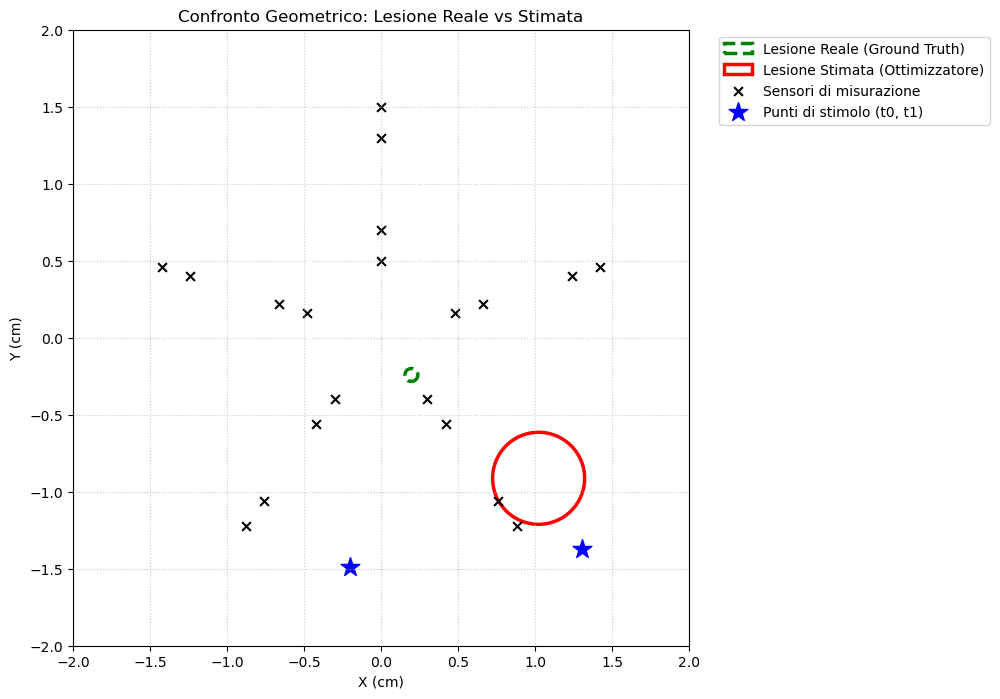

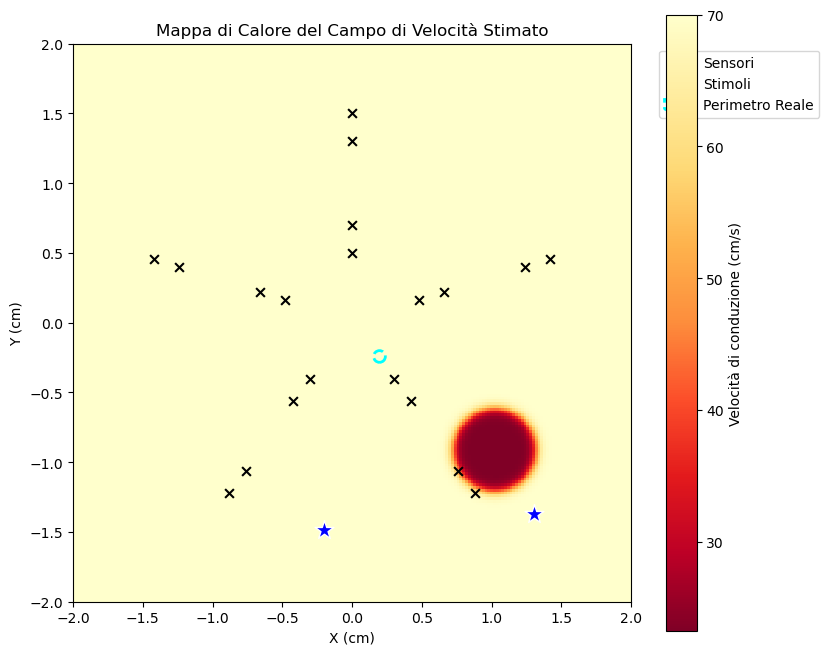

In [123]:
# Impacchetta le variabili per passarle alle funzioni di plot
target_reale_pack = [true_x, true_y, true_r]
target_stimato_pack = [pred_x, pred_y, pred_r]
impulsi_pack = [x_0, y_0, x_1, y_1]

# Richiama il Grafico Geometrico
plot_geometric_solution(
    true_target=target_reale_pack, 
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel
)

# Richiama la Mappa di Calore (assicurati che EST_V_BASE e EST_V_SLOW siano disponibili nel namespace globale)
plot_velocity_heatmap(
    true_target=target_reale_pack,
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel, 
    v_base=EST_V_BASE, 
    v_slow=EST_V_SLOW
)